# Prédiction de survie globale de patients atteints de Leucémie Myéloïde

## Description du challenge et des données

### Le challenge

L'objectif est de prédire le risque de décès des patients atteints de cancer du sang. L'estimation du pronostic du patient est essentiel afin d'adapter l'approche thérapeutique. Les patients les plus à risque pourront se voir proposer des thérapies plus intensives tandis que les patients à faible risque recevront plutôt des thérapies de soutien. \
Le challenge propose d'étudier les données réelles de 24 centre cliniques suivant des patients atteint de Leucémie.\
https://challengedata.ens.fr/challenges/162

### Les données

Nous disposons de 3 datasets :
- la cible : temps et état de survie
- les données cliniques : le centre de traitement, divers paramètres sanguins, le taux de blastes ainsi que le caryotype des patients
- les données moléculaires : mutations somatiques détécté dans les cellules cancéreuses \
\
**Nous nous concentrons ici sur les données cliniques.**

#### Le dataset cible : Survie Globale (OS)

Ce dataset contiennt 2 variables :

- ID : identifient unique pour chaque patient
- OS_YEARS : temps de survie en année depuis le diagnostic en année
- 0S_STATUS : indicateur de l'état de survie du patient lors du dernier suivi (0 : vivant, 1 : décès) \
\
Nous constatons ici une censure à droite, en effet l'événement étudié est 'décès', pour tous les patients vivant lors du dernier suivi, nous n'observons pas l'événement, nous ne pouvons donc pas déterminer quand il aura lieu pour ces patients.

#### Le dataset clinique

Ce dataset contient :
- ID : identifient unique pour chaque patient
- CENTER : le centre clinique où le patient est traité
- BM_BLAST : proportion de cellules sanguines anormales dans la moelle osseuse du patient
- WBC : nombre de globule blancs Giga/L
- ANC : nombre absolu de neutrophiles dans le sang Giga/L
- MONOCYTES : nombre de monocytes dans le sang Giga/L
- HB : niveau d'hémoglobine g/dL
- PLT : nombre de plaquettes Giga/L
- CYTOGENETICS : description du caryotype, représentant les anomalies chromosomiques dans les cellules cancéreuses du patient. Norme ISCN.

## 1. Etude exploratoire

### Importations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from leukemia.models.evaluation import HORIZON

### 1.1 Dataset cible

In [2]:
Y = pd.read_csv('../data/raw/target_train.csv')
Y = Y.set_index('ID')
print(f"Taille du dataset: {Y.shape}")
Y.head()

Taille du dataset: (3323, 2)


,OS_YEARS,OS_STATUS
ID,,
P132697,1.115068,1.0
P132698,4.928767,0.0
P116889,2.043836,0.0
P132699,2.476712,1.0
P132700,3.145205,0.0


#### 1.1.1 Données manquantes dans le dataset cible

In [3]:
Y_missing = pd.DataFrame({'Nombre de données manquantes :' : Y.isna().sum(), 'Proportion de données manquantes : (%)' : (Y.isna().sum()/Y.shape[0])*100})
Y_missing_matrix = pd.crosstab(Y['OS_YEARS'].isna(), Y['OS_STATUS'].isna())

print(Y_missing)
print(Y_missing_matrix)

           Nombre de données manquantes :  \
OS_YEARS                              150   
OS_STATUS                             150   

           Proportion de données manquantes : (%)  
OS_YEARS                                 4.513993  
OS_STATUS                                4.513993  
OS_STATUS  False  True 
OS_YEARS               
False       3173      0
True           0    150


Dans le dataset cible :
- 150 valeurs sont manquantes pour chacune des deux cibles
- pour un patient, lorsqu'il manque une donnée dans une des deux colonnes, il manque aussi la valeur pour la deuxième colonne
- la proportion de données manquantes est de 4,5 % \
\
**Il manque les données cibles pour 150 patients, nous les retirerons lors du pré-processing car il ne nous apporteront aucune information.**

#### 1.1.2 Valeurs prises par les cibles

In [4]:
print(Y.dtypes)

# 1. OS_STATUS takes 0 or 1
print(Y['OS_STATUS'].value_counts(dropna=False))

# 2. OS_YEARS < 0
print(f"Nombre de valeurs négatives: {(Y['OS_YEARS'] < 0).sum()}")
Y['OS_YEARS'].describe()

OS_YEARS     float64
OS_STATUS    float64
dtype: object
OS_STATUS
1.0    1600
0.0    1573
NaN     150
Name: count, dtype: int64
Nombre de valeurs négative: 0


count    3173.000000
mean        2.480713
std         2.588259
min         0.000000
25%         0.652055
50%         1.652055
75%         3.572603
max        22.043836
Name: OS_YEARS, dtype: float64

Types et valeurs prises par les cibles :
- OS_STATUS est de type float mais prend bien 0 ou 1
- OS_YEARS prend bien uniquement des valeurs positives
- La durée de suivi va de 0 à ~ 22ans

In [5]:
Y.groupby('OS_STATUS')['OS_YEARS'].describe()

,count,mean,std,min,25%,50%,75%,max
OS_STATUS,,,,,,,,
0.0,1573.0,2.935222,2.963922,0.00000,0.632877,2.268493,4.221918,22.043836
1.0,1600.0,2.033873,2.061487,0.00274,0.669863,1.380822,2.670548,17.375342


La durée de suivi médiane pour les patient décédés est de 1,38 ans contre 2,27 ans pour les patients censurés.

#### 1.1.3 Censure

La durée de suivi maximal est d'environ 22 ans, nous pouvons supposer qu'elle correspond à peu près à la durée de l'étude. Chaque patient a pu entrer dans l'étude à tout moment durant celle-ci. Les données sont censurées à droite : pour certains patients nous n'avons pas constaté l'événement 'décès', le suivi s'est arrété avant (soit parce que l'étude s'est terminé soit parce que le patient a été perdu de vue). Nous devons donc tenir compte de cela lors de notre analyse et modélisation car pour un patient censuré nous ne pouvons qu'affirmer qu'il a survécu au moins x années. Nous ne pouvons donc pas comparer directement les patients censurés entre eux et avec les patients décédés.

In [6]:
# 1.taux de censure, na exclus
Y_no_na = Y.dropna()
print(Y_no_na)
censoring_rate = (Y_no_na['OS_STATUS'] == 0).mean()
print(f"Taux de censure (n={Y_no_na['OS_STATUS'].sum()}): {censoring_rate:.1%}")

         OS_YEARS  OS_STATUS
ID                          
P132697  1.115068        1.0
P132698  4.928767        0.0
P116889  2.043836        0.0
P132699  2.476712        1.0
P132700  3.145205        0.0
...           ...        ...
P121826  0.547945        0.0
P121827  2.339726        0.0
P121830  1.997260        0.0
P121853  0.095890        1.0
P121834  2.290411        0.0

[3173 rows x 2 columns]
Taux de censure (n=1600.0): 49.6%


Le taux de censure est de 49,6 % (en excluant les données manquantes), ce qui représente 1600 patients. \
\
Nous étudions ensuite la censure par tranche de 6 mois de durée de suivi.

In [7]:
censoring_distribution = Y_no_na.copy()
censoring_distribution['bin'] = pd.cut(censoring_distribution['OS_YEARS'], bins = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7, 7.5, 8, 9, 10, 25], include_lowest=True)
summary = censoring_distribution.groupby('bin', observed=True)['OS_STATUS'].agg(n='count', deceased=lambda d: (d==1).sum(), censored=lambda c: (c==0).sum(), censoring_rate=lambda s: (s == 0).mean().round(2)*100)
summary

,n,deceased,censored,censoring_rate
bin,,,,
"(-0.001, 0.5]",634,296,338,53.0
"(0.5, 1.0]",466,298,168,36.0
"(1.0, 1.5]",399,258,141,35.0
"(1.5, 2.0]",260,175,85,33.0
"(2.0, 2.5]",237,139,98,41.0
"(2.5, 3.0]",186,87,99,53.0
"(3.0, 3.5]",171,71,100,58.0
"(3.5, 4.0]",167,53,114,68.0
"(4.0, 4.5]",149,65,84,56.0


<Axes: xlabel='OS_YEARS', ylabel='Count'>

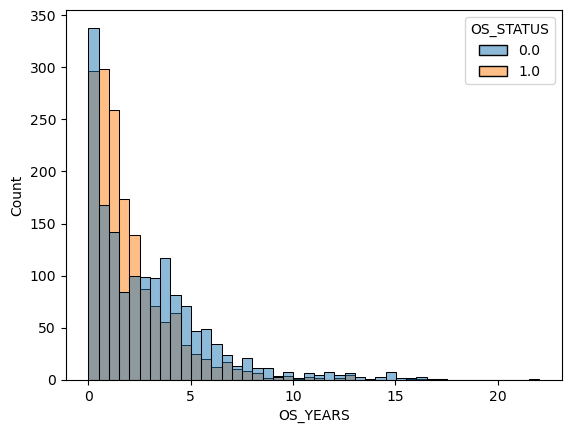

In [8]:
sns.histplot(censoring_distribution, x=censoring_distribution['OS_YEARS'], hue=censoring_distribution['OS_STATUS'], bins=44)

- Le taux de censure global (na exclus, n= 3173) : 49,6 %
- Le nombre de décès diminue plus  la durée de suivi augmente : suggère une letalité précoce forte
- Le nombre de censurés est assez important pour les suivis 0-6 mois (338 patients) le suivi s'est donc terminé rapidement sans que l'on constate le décès pour ces patients. Cela peut être due à plusieurs choses :
  - un important groupe de patients recrutés à la fin de l'étude
  - un certain nombre de patients ont été perdus de vue
  - les centres ne suivent pas les patients de la même manière
- Le taux de censure diminue au début (durant les 2 premières années) puis augmente ensuite. Cela est assez logique, les patients avec un suivi long sont ceux qui survivent à la phase de forte lethalité du début. Leur suivi dépasse sans doute la fin de l'étude et sont donc censurés.

### 1.2 Dataset clinique

In [9]:
X_clinical = pd.read_csv('../data/raw/X_train/clinical_train.csv')
X_clinical = X_clinical.set_index('ID')
X_clinical.head()

,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTOGENETICS
ID,,,,,,,,
P132697,MSK,14.0,2.8,0.2,0.7,7.6,119.0,"46,xy,del(20)(q12)[2]/46,xy[18]"
P132698,MSK,1.0,7.4,2.4,0.1,11.6,42.0,"46,xx"
P116889,MSK,15.0,3.7,2.1,0.1,14.2,81.0,"46,xy,t(3;3)(q25;q27)[8]/46,xy[12]"
P132699,MSK,1.0,3.9,1.9,0.1,8.9,77.0,"46,xy,del(3)(q26q27)[15]/46,xy[5]"
P132700,MSK,6.0,128.0,9.7,0.9,11.1,195.0,"46,xx,t(3;9)(p13;q22)[10]/46,xx[10]"


#### 1.2.1 Données manquantes

In [10]:
X_clinic_miss_by_feat = pd.DataFrame({'Nombre de données manquantes': X_clinical.isna().sum(), 'Proportion de données manquantes (%)': (X_clinical.isna().sum() / X_clinical.shape[0]) * 100})
X_clinic_miss_by_feat

,Nombre de données manquantes,Proportion de données manquantes (%)
CENTER,0,0.000000
BM_BLAST,109,3.280169
WBC,272,8.185375
ANC,193,5.808005
MONOCYTES,601,18.086067
HB,110,3.310262
PLT,124,3.731568
CYTOGENETICS,387,11.646103


Il manque beaucoup de données pour certaines features (MONOCYTES par exemple). \
Etudions les données manquantes par centres cliniques.

<Axes: ylabel='CENTER'>

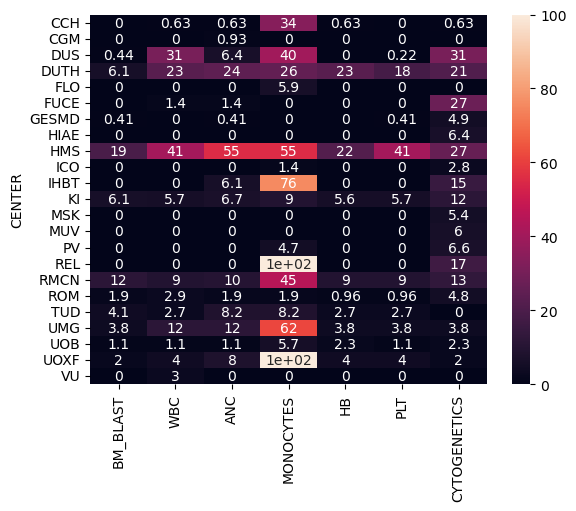

In [11]:
X_clinic_miss_by_center = X_clinical.groupby('CENTER')[X_clinical.columns.drop(['CENTER'])].apply(lambda g: g.isna().mean() * 100)
sns.heatmap(X_clinic_miss_by_center, annot=True)

- Il y a beaucoup de données manquantes pour MONOCYTES (18,1 %) CYTOGENETICS (11,6 %) et WBC (8,2 %)
- Les centres REL et UOXF n'ont pas collecté les MONOCYTES, nous ne pourrons donc pas envisager un remplacement des valeurs manquantes par centre
- Les valeurs manquantes sont sur-représentées dans certains centres : HMS & DUTH
- Les valeurs manquantes ne semblent pas être réparties aléatoirement entre les centres, surtout pour MONOCYTES, WBC, ANC et PLT
- Les valeurs manquantes pour BM_BLAST et HB features semblent un peu plus aléatoirement distribuées entre les centres  \
\
**Les valeurs manquantes ne sont pas distribuées aléatoirement dans le dataset clinique, nous devrons en tenir compte au moment de les remplacer.**

#### 1.2.2 Distribution des paramètres sanguins

Nous étudions ici la distribution des paramètres sanguins.

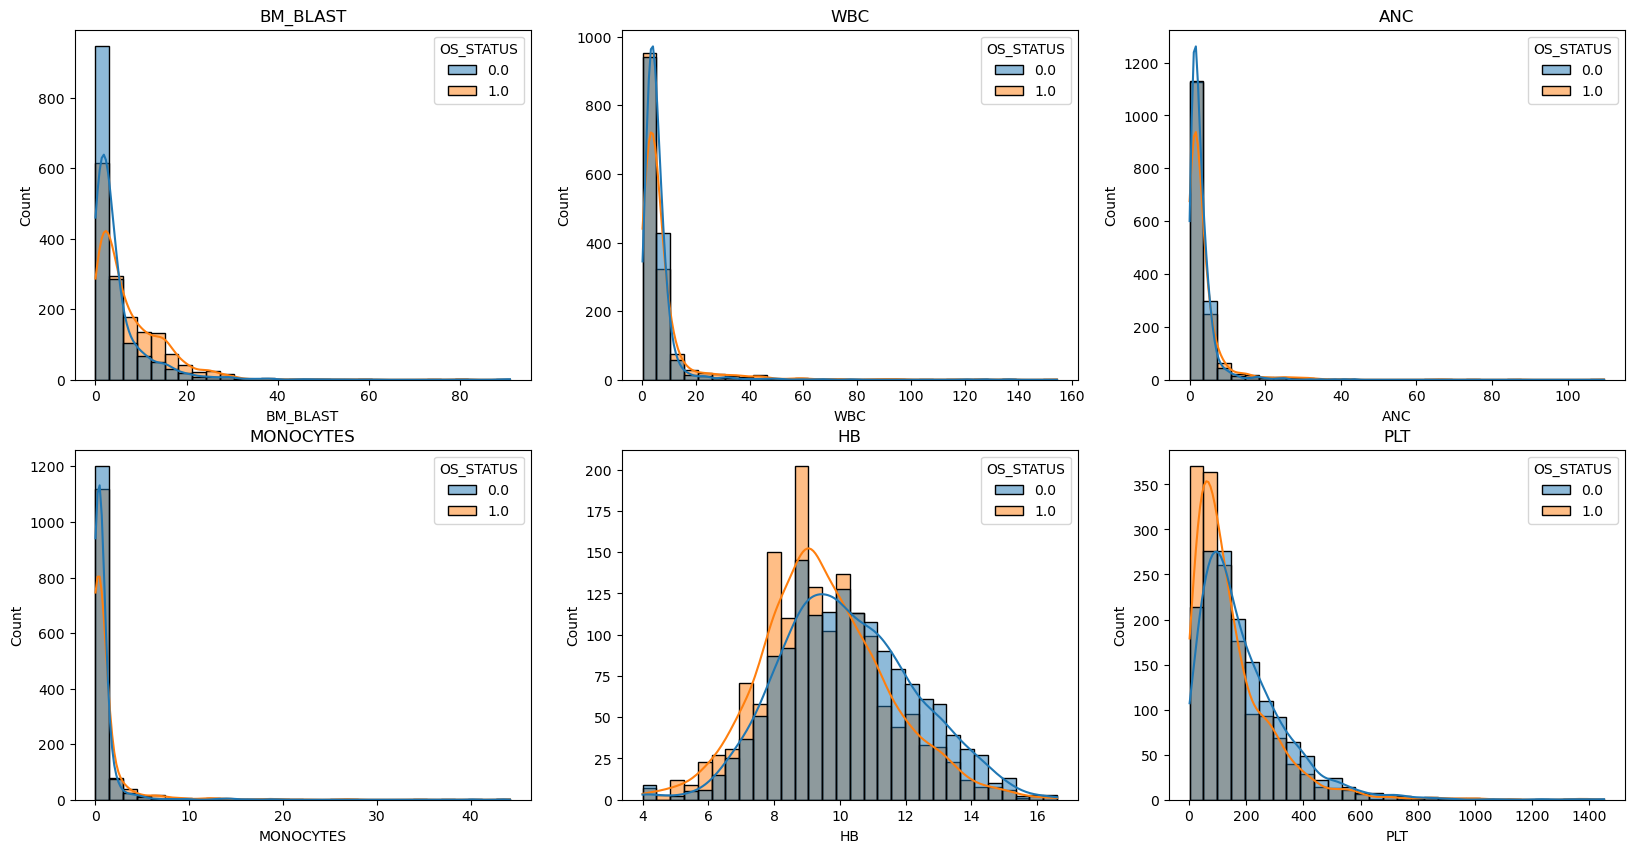

In [12]:
hemo_var = ['BM_BLAST', 'WBC', 'ANC', 'MONOCYTES', 'HB', 'PLT'] # paramètres sanguins

df_status = X_clinical.join(Y['OS_STATUS'], how='inner')   # alignement par ID (index)
df_status = df_status[df_status['OS_STATUS'].notna()]

fig, axes = plt.subplots(2,3, figsize= (20, 10))
axes = axes.flatten()

# Distribution des paramètres sanguis par statuts
for var, ax in zip(hemo_var, axes):
    sns.histplot(data=df_status, x=var, hue='OS_STATUS', bins=30, kde=True, ax=ax)
    ax.set_title(var)

Distribution :
- BM_BLAST, WBC, ANC, MONOCYTES et PLT sont asymétriques.
- HB est approximativement symétrique.
- MONOCYTES, ANC et WBC sont très concentrés autour des petites valeurs.
- PLT et BM_BLAST sont moins concentré.

*Il y a les mêmes proportions des patients censuré et non censuré dans notre dataset.*

Distribution en fonction du statut :
- Pour BM_BLAST, les patients censurés sont concentrés sur les petites valeurs
- Pour ANC, WBC et MONOCYTES on n'observe pas de différence flagrante de distribution
- Pour PLT les patients décédés semblent concentrés sur les petites valeurs
- Pour HB les patients décèdés la distribution semble être légèrement décalée sur les petites valeurs par rapport aux patients censurés \
\
Afin de symétriser la distribution et de réduire l'impact des résidus sur le modèle linéaire de COX, nous passerons au log les covariables à la distribution asymétrique. Nous devrons faire attention aux variables qui peuvent prendre 0 (comme BM_BLAST, MONOCYTES, ...).

#### 1.2.3 Centres

Nous étudions dans cette partie la covariable centre.

In [13]:
print(f"Nombre de centres manquants : {X_clinical['CENTER'].isna().sum()}")
print(f"Nombre de centres differents : {X_clinical['CENTER'].nunique()}")
center_counts = X_clinical['CENTER'].value_counts()
center_counts.describe()

Nombre de centres manquants : 0
Nombre de centres differents : 23


count     23.000000
mean     144.478261
std      195.356520
min        6.000000
25%       48.500000
50%       73.000000
75%      133.000000
max      900.000000
Name: count, dtype: float64

Il y a 23 centres différents. Le nombre de patients par centre varie fortement : entre 6 et 900. Nous devrons en tenir compte si nous décidons de remplacer les données manquantes avec des valeurs calculées par centres.\
Nous nous intéressons ensuite au taux de décès et censure par centre.

In [14]:
center_x_os_status = pd.crosstab(X_clinical['CENTER'], Y['OS_STATUS'], normalize='index')
center_x_os_status

OS_STATUS,0.0,1.0
CENTER,,
CCH,0.764286,0.235714
CGM,0.654206,0.345794
DUS,0.352809,0.647191
DUTH,0.409091,0.590909
FLO,0.852941,0.147059
FUCE,0.465753,0.534247
GESMD,0.542857,0.457143
HIAE,0.425532,0.574468
HMS,0.392157,0.607843


Les taux de décès et de censure semblent varier en fonction du centre. Le centre pourrait donc avoir un effet sur notre prédiction. Certains centres ont un écart important entre le taux de décès et censure MUV (91,5% de décès), ROM (89% de censure). Cela suggère un potentiel impact de la covariable centre sur la prédiction de survie globale.

#### 1.2.4 Caryotypes

Nous nous interessons maintenant à la variable CYTOGENETICS, qui indique en norme ISCN le caryotype du patient.

In [15]:
print(f"Nombre de données manquantes pour le caryotype : {X_clinical['CYTOGENETICS'].isna().sum()}")
print(f"Nombre de caryotypes uniques : {X_clinical['CYTOGENETICS'].nunique()}")

cyto_counts = X_clinical['CYTOGENETICS'].value_counts()

print(f"Nombre de caryotypes portés par un seul patient : {(cyto_counts == 1).sum()}")
print(f"Nombre de patients qui ont un des 15 caryotypes les plus frequent du dataset : {cyto_counts.head(15).sum()}")

Nombre de données manquantes pour le caryotype : 387
Nombre de caryotypes uniques : 1194
Nombre de caryotypes portés par un seul patient : 1075
Nombre de patients qui ont un des 15 caryotypes les plus frequent du dataset : 1428


- On observe 1194 caryotypes différents
- 1075 caryotypes ne sont portés que par un seul patient
- 1428 patients ont un des 15 caryotypes les plus fréquents du dataset \
Nous devrons donc trouver un moyen de regrouper les caryotypes en catégories.

On définit le caryotype normal comme étant : 46 suivi de xx ou xy suivi d'un nombre optionnel [n]. \
Le regex permettant de les sélectionner est : r'46,(xx|xy)(\[\d+\])?$'.

In [16]:
is_normal = X_clinical['CYTOGENETICS'].str.match(r'46,(xx|xy)(\[\d+\])?$', case=False)
print(f"Nombre de patients avec un caryotype normal : {X_clinical[is_normal == True]['CYTOGENETICS'].shape[0]}")

Nombre de patients avec un caryotype normal : 1689


Nous comptons ici 1689 patients avec un caryotype normal. Cependant, il est possible qu'une partie de ces patients ait un clone avec un caryotype anormal spécifié ensuite. En effet le regex sélectionne tous les patients pour lesquels l'entrée commence par un caryotype normal.

#### Conclusion de l'étude exploratoire

La cohorte contient 3323 patients, 3173 d'entre eux (95.5%) ont une entrée dans le dataset cible, et 150 d'entre eux n'en ont pas. Notre cible est censurée à droite, avec un taux de censure de 49,6 %. Les décès sont assez concentrés durant les premières années (médiane de durée de suivi pour les décès de 1,38 ans) qui suggère une mortalité précoce forte. Les paramètres hématologiques  ont une distribution asymétrique avec une part importante de résidus, excepté HB. Ces résidus semblent représenter une population de patients. Les données manquantes ne sont pas distribuées aléatoirement et il en manque nettement plus pour certains paramètres et dans certains centres : MONOCYTES (18,1%), CYTOGENETICS (11,6%) et WBC (8,2%).

## 2. Pré-processing

#### 2.1 Jointure des datasets

Afin de traiter la cible et le dataset clinique en même temps et les aligner nous réalisons une jointure sur 'ID' l'identifiant unique du patient. Nous avons vérifié au préalable que tous les ID de la cible sont présents exactement une fois dans le dataset clinique.

In [17]:
X_clinical_preprocessing = pd.read_csv('../data/raw/X_train/clinical_train.csv')
Y_preprocessing = pd.read_csv('../data/raw/target_train.csv')

def join_clinical_target(X_clinical:pd.DataFrame, Y:pd.DataFrame) -> pd.DataFrame:
    """
    Joining the two dataframes into a single dataframe, one to one on 'ID'
    :param X_clinical: the clinical features dataset
    :param Y: the target dataset
    :return: the merge dataframe
    """
    X, y = X_clinical.copy(), Y.copy()

    merge = pd.merge(X, y, how='left', on='ID', validate='one_to_one')
    merge.set_index('ID', inplace=True)
    return merge

clinical_dataset_preprocessing = join_clinical_target(X_clinical_preprocessing, Y_preprocessing)
print(f"Taille du dataset joint : {clinical_dataset_preprocessing.shape}")
clinical_dataset_preprocessing.head()

Taille du dataset joint : (3323, 10)


,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTOGENETICS,OS_YEARS,OS_STATUS
ID,,,,,,,,,,
P132697,MSK,14.0,2.8,0.2,0.7,7.6,119.0,"46,xy,del(20)(q12)[2]/46,xy[18]",1.115068,1.0
P132698,MSK,1.0,7.4,2.4,0.1,11.6,42.0,"46,xx",4.928767,0.0
P116889,MSK,15.0,3.7,2.1,0.1,14.2,81.0,"46,xy,t(3;3)(q25;q27)[8]/46,xy[12]",2.043836,0.0
P132699,MSK,1.0,3.9,1.9,0.1,8.9,77.0,"46,xy,del(3)(q26q27)[15]/46,xy[5]",2.476712,1.0
P132700,MSK,6.0,128.0,9.7,0.9,11.1,195.0,"46,xx,t(3;9)(p13;q22)[10]/46,xx[10]",3.145205,0.0


#### 2.2 Géstion des valeurs manquantes

##### 2.2.1 Gestion des données manquantes dans la cible

Nous supprimons les patients qui ont des données manquantes pour la cible. En effet, les patients n'ayant pas de données pour la cible ne nous apportent pas d'information.

In [18]:
def drop_missing_target(merged:pd.DataFrame) -> tuple:
    """
    Drop the missing target
    :param merged: the merged dataframe
    :return: the dataset without missing target and the number of missing targets
    """
    out = merged.copy()
    out.dropna(subset=['OS_YEARS', 'OS_STATUS'], inplace=True)
    n_dropped = len(merged) - len(out)
    return out, n_dropped

clinical_dataset_preprocessing, n_dropped = drop_missing_target(clinical_dataset_preprocessing)
print(f"{n_dropped} patients exclus")
print(f"Nouvelle taille du dataset: {clinical_dataset_preprocessing.shape}")
clinical_dataset_preprocessing[['OS_YEARS', 'OS_STATUS']].isna().sum()

150 patients exclus
Nouvelle taille du dataset: (3173, 10)


OS_YEARS     0
OS_STATUS    0
dtype: int64

##### 2.2.2 Gestions des valeurs manquantes dans le dataset clinique

Les données manquantes dans le dataset clinique ne semblent pas être aléatoirement distribuées.
- Pour les paramètres biologiques : nous choisissons de les remplacer par la médiane des valeurs qui sera calculée sur le X_train dans le pipeline afin d'éviter les fuites. Nous ajoutons également une feature booléenne PARAM_MISSING pour chaque paramètres biologiques, indiquant si la valeur est manquante ou non pour chaque patient.
- Pour les caryotypes : nous choisissons de créer une feature booléenne MISSING qui indiquera que le caryotype est manquant. (Nous réaliserons cette feature dans la partie consacrée à CYTOGENETICS).

In [19]:
hemo_param = ['BM_BLAST', 'WBC', 'ANC', 'MONOCYTES', 'HB', 'PLT']

def add_missing_indicator(clinical_dataset: pd.DataFrame, hemo_parameters=hemo_param) -> pd.DataFrame:
    """
    Add missing value indicators for the blood parameters
    :param clinical_dataset: the clinical dataset we are transforming
    :param hemo_parameters: the list of blood parameters
    :return: the clinical dataset with missing indicators
    """
    out = clinical_dataset.copy()
    for var in hemo_parameters:
        out[var + '_MISSING'] = out[var].isna().astype(int)
    return out


In [20]:
clinical_dataset_preprocessing = add_missing_indicator(clinical_dataset_preprocessing)
clinical_dataset_preprocessing.head()

,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTOGENETICS,OS_YEARS,OS_STATUS,BM_BLAST_MISSING,WBC_MISSING,ANC_MISSING,MONOCYTES_MISSING,HB_MISSING,PLT_MISSING
ID,,,,,,,,,,,,,,,,
P132697,MSK,14.0,2.8,0.2,0.7,7.6,119.0,"46,xy,del(20)(q12)[2]/46,xy[18]",1.115068,1.0,0,0,0,0,0,0
P132698,MSK,1.0,7.4,2.4,0.1,11.6,42.0,"46,xx",4.928767,0.0,0,0,0,0,0,0
P116889,MSK,15.0,3.7,2.1,0.1,14.2,81.0,"46,xy,t(3;3)(q25;q27)[8]/46,xy[12]",2.043836,0.0,0,0,0,0,0,0
P132699,MSK,1.0,3.9,1.9,0.1,8.9,77.0,"46,xy,del(3)(q26q27)[15]/46,xy[5]",2.476712,1.0,0,0,0,0,0,0
P132700,MSK,6.0,128.0,9.7,0.9,11.1,195.0,"46,xx,t(3;9)(p13;q22)[10]/46,xx[10]",3.145205,0.0,0,0,0,0,0,0


#### 2.2.3 Paramètres biologiques

Nous choisissons de passer les paramètres biologiques, qui ont une distribution asymétrique, au log. Nous utilisons log1p car certains paramètres peuvent prendre la valeur 0.

In [21]:
hemo_param_log = ['BM_BLAST', 'WBC', 'ANC', 'MONOCYTES', 'PLT']

def log_transform(clinical_dataset: pd.DataFrame, hemo_parameters_log=hemo_param_log) -> pd.DataFrame:
    """
    Log1p transforming of the right-skewed blood parameters
    :param clinical_dataset: the clinical dataset we are transforming
    :param hemo_parameters_log: the list of the right-skewed blood parameters
    :return: the transformed clinical dataset
    """
    out = clinical_dataset.copy()
    for var in hemo_parameters_log:
        out[var] = np.log1p(out[var])
    out.rename(columns={v: f'{v}_LOG' for v in hemo_parameters_log}, inplace=True)
    return out

In [22]:
clinical_dataset_preprocessing = log_transform(clinical_dataset_preprocessing)
clinical_dataset_preprocessing.head()

,CENTER,BM_BLAST_LOG,WBC_LOG,ANC_LOG,MONOCYTES_LOG,HB,PLT_LOG,CYTOGENETICS,OS_YEARS,OS_STATUS,BM_BLAST_MISSING,WBC_MISSING,ANC_MISSING,MONOCYTES_MISSING,HB_MISSING,PLT_MISSING
ID,,,,,,,,,,,,,,,,
P132697,MSK,2.708050,1.335001,0.182322,0.530628,7.6,4.787492,"46,xy,del(20)(q12)[2]/46,xy[18]",1.115068,1.0,0,0,0,0,0,0
P132698,MSK,0.693147,2.128232,1.223775,0.095310,11.6,3.761200,"46,xx",4.928767,0.0,0,0,0,0,0,0
P116889,MSK,2.772589,1.547563,1.131402,0.095310,14.2,4.406719,"46,xy,t(3;3)(q25;q27)[8]/46,xy[12]",2.043836,0.0,0,0,0,0,0,0
P132699,MSK,0.693147,1.589235,1.064711,0.095310,8.9,4.356709,"46,xy,del(3)(q26q27)[15]/46,xy[5]",2.476712,1.0,0,0,0,0,0,0
P132700,MSK,1.945910,4.859812,2.370244,0.641854,11.1,5.278115,"46,xx,t(3;9)(p13;q22)[10]/46,xx[10]",3.145205,0.0,0,0,0,0,0,0


#### 2.2.4 Variable CYTOGENETICS

Dans un premier temps nous choissisons de créer 4 features pour exploiter cette variable :
- CYTO_NORMAL : vrai si le caryotype est de type normal.
- CYTO_ABNORMAL: vrai si le caryotype est de type anormal ou de type complex.
- CYTO_COMPLEX: vrai si le caryotype est de type complex. Les patients qui ont un caryotypes complex ont vrai pour CYTO_COMPLEX et CYTO_ABNORMAL.
- CYTO_MISSING: vrai si le caryotype est manquant.

In [23]:
def add_cytogenetics_flags(clinical_dataset:pd.DataFrame) -> pd.DataFrame:
    """
    Add cytogenetics flags: Normal, Abnormal, Complex and Missing. A Complex karyotype is also Abnormal.
    :param clinical_dataset: the clinical dataset we are transforming
    :return: the transformed clinical dataset with cytogenetics flags
    """
    out = clinical_dataset.copy()
    cyto = out['CYTOGENETICS']
    # Creating masks
    is_missing = cyto.isna()
    is_normal = cyto.str.match(r'46,(xx|xy)(\[\d+\])?$', case=False, na=False)
    is_complex = cyto.str.match('complex', case=False, na=False)

    # Creating the normal feature
    out['CYTO_NORMAL'] = (is_normal & ~is_missing).astype(int)
    # Creating the complex feature
    out['CYTO_COMPLEX'] = (is_complex & ~is_missing).astype(int)
    # Creating the abnormal feature
    out['CYTO_ABNORMAL'] = (~is_normal & ~is_missing).astype(int)
    # Creating the missing feature
    out['CYTO_MISSING'] = (is_missing).astype(int)

    out.drop(columns= 'CYTOGENETICS', inplace=True)

    return out

In [24]:
clinical_dataset_preprocessing = add_cytogenetics_flags(clinical_dataset_preprocessing)
clinical_dataset_preprocessing.head()

,CENTER,BM_BLAST_LOG,WBC_LOG,ANC_LOG,MONOCYTES_LOG,HB,PLT_LOG,OS_YEARS,OS_STATUS,BM_BLAST_MISSING,WBC_MISSING,ANC_MISSING,MONOCYTES_MISSING,HB_MISSING,PLT_MISSING,CYTO_NORMAL,CYTO_COMPLEX,CYTO_ABNORMAL,CYTO_MISSING
ID,,,,,,,,,,,,,,,,,,,
P132697,MSK,2.708050,1.335001,0.182322,0.530628,7.6,4.787492,1.115068,1.0,0,0,0,0,0,0,0,0,1,0
P132698,MSK,0.693147,2.128232,1.223775,0.095310,11.6,3.761200,4.928767,0.0,0,0,0,0,0,0,1,0,0,0
P116889,MSK,2.772589,1.547563,1.131402,0.095310,14.2,4.406719,2.043836,0.0,0,0,0,0,0,0,0,0,1,0
P132699,MSK,0.693147,1.589235,1.064711,0.095310,8.9,4.356709,2.476712,1.0,0,0,0,0,0,0,0,0,1,0
P132700,MSK,1.945910,4.859812,2.370244,0.641854,11.1,5.278115,3.145205,0.0,0,0,0,0,0,0,0,0,1,0


## 3. Feature engineering

Nous avons, durant le préprocessing simplifié la variable CYTOGENETICS. \
Nous l'avions transformée en 4 features :
- Normal
- Abnormal
- Complex
- Missing

Nous considérions tous les caryotypes anormaux comme équivalent, cependant ils ne le sont pas. La littérature suggère que des caryotypes anormaux sont protecteurs et définit les catégories suivantes : abnormal karyotypes favorable, intermediate and adverse. https://pmc.ncbi.nlm.nih.gov/articles/PMC4874200/

Les caryotypes identifiés et classés sont les suivants :
- Very good: del(11q) -Y
- Good: Normal, del(5q) (single and double), del(12p), del(20q),
- Intermediate: del(7), +8, i(17q), +19, any double, any other single
- Poor : single: inv(3), t(3q), del(3q), -7 ; double: -7 del(7q) complex = 3 anomaly
- Very poor: complex > 3 anomaly

Pour compter le nombre d'anomalies nous allons utiliser un proxy : nous comptons le nombre de virgules -1 pour retirer celle qui sépare le nombre de chromosome du reste du caryotype. \
\
Nous devons tenir compte du fait que la norme ISCN n'est pas toujours respectée ou que plusieur versions de celle-ci sont présentes dans le dataset. \
\
Pour éviter les répétitions nous créons une fonction qui recrée en regex le pattern de la délétion : del(5q) can be del(5q), del(5)(q5), del5q, 5q- --> del\({chrom}({arm}|\({arm})|del{chrom}{arm}|{chrom}{arm}-

In [25]:
def patern_del_arm(chrom: str, arm: str) -> str:
    """Cover del(20q), del(20)(q12) and free labels del20q/20q-."""
    return rf"del\({chrom}({arm}|\({arm}|\)\({arm})|del{chrom}{arm}|{chrom}{arm}-"

def count_abnormalities(cyto: str) -> int:
    """
    Count the number of abnormalities in the most abnormal clone of the karyotype
    :param cyto: the karyotype of the patient
    :return: the number of abnormalities
    """
    return max(c.count(",") - 1 for c in cyto.split("/"))

In [26]:
def pronostic_cyto (clinical_dataset:str) -> pd.DataFrame:
    """
    Add the a new feature with categories indicating the pronostic per karyotype
    :param clinical_dataset: the clinical dataset
    :return: the dataset with the new feature and without CYTOGENETICS
    """
    cyto = clinical_dataset['CYTOGENETICS']
    out = clinical_dataset.copy()
    # Number of abnormaalities
    n_abn = cyto.fillna("").map(count_abnormalities)

    # Masks
    is_missing = cyto.isna()
    is_normal = cyto.str.match(r'46,(xx|xy)(\[\d+\])?$', case=False, na=False)
    is_complex = cyto.str.match ('complex', case=False, na=False) | (n_abn == 3)
    is_very_good = cyto.str.contains(rf'({patern_del_arm('11','q')}|-Y)', case=False, na=False)
    is_good = cyto.str.contains(rf'({patern_del_arm('5','q')}|{patern_del_arm('12','p')}|{patern_del_arm('20','q')})' , case=False, na=False)
    is_intermediate = cyto.str.contains(rf'({patern_del_arm('7','q')}|\+8|i\(17(q|\(q)|\+19)', case=False, na=False)
    is_poor = cyto.str.contains(rf'(inv\(3\)|t\(3;3|{patern_del_arm('3','q')}|-7)' , case=False, na=False) | cyto.str.match ('complex', case=False, na=False) | (n_abn == 3)
    is_very_poor = (n_abn > 3) | cyto.str.contains('>3abnormalities', case=False, na=False)

    conditions = [is_missing, is_normal, is_very_poor, is_poor, is_good, is_very_good]
    cyto_categories = ["MISSING", "NORMAL", "VERY_POOR", "POOR", "GOOD", "VERY_GOOD"]
    out["CYTO_LVL"] = np.select(conditions, cyto_categories, default="INTERMEDIATE")
    out.drop('CYTOGENETICS', axis=1, inplace=True)
    return out


## 4. Protocole d'évaluation

#### Imports

Nous utilisons le package scikit-survival qui est bati sur scikit-learn et qui est dédié à l'étude de durée de survie.

In [27]:
from sksurv.util import Surv
from sklearn.model_selection import StratifiedKFold
from sksurv.metrics import concordance_index_ipcw

#### 4.1 Découpage du dataset clinique en X et y.

In [28]:
def split_clinical_processed(clinical_train_processed_path) -> pd.DataFrame:
    """
    Loading the CSV dataset as a pandas dataframe
    :param clinical_train_processed_path: path of the processed clinical train file
    :return: the features and labels datasets
    """
    clinical_dataset = pd.read_csv(clinical_train_processed_path, index_col=0)
    Y = clinical_dataset[['OS_YEARS', 'OS_STATUS']]
    X = clinical_dataset.drop(['OS_YEARS', 'OS_STATUS'], axis=1)
    return X, Y

In [29]:
X_clinical_evaluation, Y_evaluation = split_clinical_processed('../data/processed/clinical_train_processed_v1.csv')
print(f"Taille de y : {Y_evaluation.shape}")
print(f"Taille de X : {X_clinical_evaluation.shape}")

Taille de y : (3173, 2)
Taille de X : (3173, 17)


#### 4.2 Transformation de y en matrice structuré

Nous allons utiliser une metrique (IPCW C-index et un modèle COX) qui prennent en entrée une matrice structurée pour y. Nous pouvons facilement construire cette matrice avec la fonction from_arrays du module Surv.

In [30]:
def make_surv_target(os_years: pd.Series, os_status: pd.Series) -> np.ndarray:
    """
    Build the structured array for the survival target
    :param os_years: follow-up duration
    :param os_status: status of the patient at the end of the follow-up
    :return:
    """
    return Surv.from_arrays(event=os_status.astype(bool), time=os_years)
y_str = make_surv_target(Y_evaluation['OS_YEARS'], Y_evaluation['OS_STATUS'])
y_str

array([( True, 1.11506849), (False, 4.92876712), (False, 2.04383562), ...,
       (False, 1.99726027), ( True, 0.09589041), (False, 2.29041096)],
      shape=(3173,), dtype=[('event', '?'), ('time', '<f8')])

#### 4.3 Split du dataframe pour l'entrainnement

Nous utilisons un StratifiedKFold pour garantir la même proportion de censure et de décès dans nos sets d'entrainement et de validation. Nous mélangeons avec shuffle car les patients sont triés par centre.

In [31]:
def get_cv(n_fold: int, seed: int=42) -> StratifiedKFold:
    """
    Create a StratifiedKFold CV
    :param n_fold: number of folds
    shuffle=True : the dataset may be sorted by center
    :return: StratifiedKFold
    """
    return StratifiedKFold(n_splits=n_fold, shuffle=True, random_state=seed)

In [32]:
skf = get_cv(5)

status = Y_evaluation['OS_STATUS'].astype(int)
folds = list(skf.split(X_clinical_evaluation, status))

for train_idx, val_idx in folds:
    print(f"Train: {np.bincount(status.iloc[train_idx])}, Val: {np.bincount(status.iloc[val_idx])}")

Train: [1258 1280], Val: [315 320]
Train: [1258 1280], Val: [315 320]
Train: [1258 1280], Val: [315 320]
Train: [1259 1280], Val: [314 320]
Train: [1259 1280], Val: [314 320]


Vérification que tous les patients apparaissent une et une seule fois.

In [33]:
all_val_idx = np.concatenate([val_idx for _, val_idx in folds])

print(len(all_val_idx))                    # 3173 (tous les patients, une fois chacun)
print(len(np.unique(all_val_idx)))         # 3173 (unicité des patients)
print(np.array_equal(np.sort(all_val_idx), np.arange(len(X_clinical_evaluation))))  # True (couverture exact)

3173
3173
True


#### 4.4 Metric : IPCW C-index

Le C-index est une métrique qui compare les paires de patients comparable deux à deux et qui vérifie si l'ordre dans lequel le modèle les a classé est le bon. Il calcule la proportion des paires comparables pour lesquelles les prédictions des risques de décès du modèle sont dans le bon ordre par rapport à leurs temps de survie réels.
Une paire comparable :
- deux décès
- un décès et une censure intervenue à un temps plus long (l'événement doit avoir eu lieu pour le patient 1 avant que le patient 2 ne soit censuré. \
Prend en compte la censure : cet indice applique un poids à chaque individu qui est l'inverse de la probabilité de censure à l'instant t (durée de suivi de l'individu).

In [34]:
HORIZON = 7.0
def ipcw_c_index(y_train, y_val, risk_scores, tau=HORIZON) -> float:
    """
    Calculates the C-index
    :param risk_scores: the output of the model
    :param y_train: to estimate the distribution of the censoring
    :param y_val: validation labels
    :return: C-index at horizon HORIZON
    """
    return concordance_index_ipcw(y_train, y_val, risk_scores, tau=tau)[0]

#### 4.5 Baseline : BM_BLAST

Le taux de blast est un indicateur fort du pronostic de la maladie. Nous regardons ici comment une prédiction baséé uniquement sur ce taux de blast s'en sort.

In [35]:
def baseline_blast(X,Y):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    status = Y['OS_STATUS'].astype(int)
    folds = list(skf.split(X, status))
    y_baseline = make_surv_target(Y['OS_YEARS'], Y['OS_STATUS'])
    fold_score = []
    for train_idx, val_idx in folds:
        # replacing the nan by the median
        med = X['BM_BLAST_LOG'].iloc[train_idx].median()

        # estimated the risk score by the level of blasts
        baseline_scores = X['BM_BLAST_LOG'].iloc[val_idx].fillna(med).to_numpy()

        # calculating the C-index for the fold
        c=ipcw_c_index(y_baseline[train_idx], y_baseline[val_idx], baseline_scores)
        fold_score.append(c)

    return fold_score

X,Y = split_clinical_processed('../data/processed/clinical_train_processed.csv')
fold_score_baseline_blast = baseline_blast(X,Y)
print(f'Baseline BM_BLAST C-index: {np.mean(fold_score_baseline_blast)} ± {np.std(fold_score_baseline_blast)}')

Baseline BM_BLAST C-index: 0.6155579439299809 ± 0.008839322364962954


Le taux de Blast, utilisé comme indicateur de risque, donne un C-index de 0,6156 ± 0.0088. Le modèle devra battre cette base. \
Le resultats par folds sont stockés dans fold_score_baseline_blast.

## 5. Modélisation

In [36]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import train_test_split
from leukemia.models import evaluation
from leukemia.data import loader
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import  make_pipeline
from sklearn.impute import SimpleImputer
from sksurv.linear_model import CoxPHSurvivalAnalysis
from scipy.stats import ttest_rel


### Importing data

In [37]:
X, y = loader.split_clinical_processed("../data/processed/clinical_train_processed_v1.csv")

num_cols = ['BM_BLAST_LOG', 'WBC_LOG', 'ANC_LOG', 'MONOCYTES_LOG', 'HB',
       'PLT_LOG', 'BM_BLAST_MISSING', 'WBC_MISSING',
       'ANC_MISSING']
binary_cols = ['MONOCYTES_MISSING', 'HB_MISSING', 'PLT_MISSING',
       'CYTO_NORMAL', 'CYTO_COMPLEX', 'CYTO_ABNORMAL', 'CYTO_MISSING']

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### 5.1 Baseline : LGBoost

Nous utilisons le preprocessing version 1 :
- Indicateurs de valeur manquantes pour les paramètres biologiques
- Paramètres biologiques passés au log
- 4 variables pour décrire le caryotype :
  - normal
  - missing
  - abnormal
  - complex

Nous créons ensuite preprocess_base transformer pour :
- Standardiser les covariables numériques
- Remplacer les valeurs numériques manquantes par la médiane
- Encoder en OneHot la covariable CENTER

In [39]:
preprocess_LGB = ColumnTransformer([
    ("num", "passthrough", num_cols),("binary", "passthrough", binary_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['CENTER']),
])

mod_pipe_LGB = LGBMRegressor()

pipe_LGB = make_pipeline(preprocess_LGB, mod_pipe_LGB)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scorer = evaluation.ipcw_c_index
scores = []

for fold, (train_index, val_index) in enumerate(cv.split(X_train, y_train["OS_STATUS"])):
    X_train_cv, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_train_cv, y_val = y_train.iloc[train_index], y_train.iloc[val_index]

    pipe_LGB.fit(X_train_cv, y_train_cv['OS_YEARS'])

    y_train_cv = loader.make_surv_target(y_train_cv['OS_YEARS'], y_train_cv['OS_STATUS'])
    y_val = loader.make_surv_target(y_val['OS_YEARS'], y_val['OS_STATUS'])

    scores.append({"fold": fold, "train_sore": scorer(y_train_cv, y_train_cv, -pipe_LGB.predict(X_train_cv)),
    "val_sore": scorer(y_train_cv, y_val, -pipe_LGB.predict(X_val))})

scores = pd.DataFrame(scores)
print(scores, scores["val_sore"].mean(), scores["val_sore"].std())

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000526 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1258
[LightGBM] [Info] Number of data points in the train set: 1903, number of used features: 33
[LightGBM] [Info] Start training from score 2.532215


/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000400 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1264
[LightGBM] [Info] Number of data points in the train set: 1903, number of used features: 35
[LightGBM] [Info] Start training from score 2.458076


/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000321 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1266
[LightGBM] [Info] Number of data points in the train set: 1903, number of used features: 35
[LightGBM] [Info] Start training from score 2.433016


/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000395 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1268
[LightGBM] [Info] Number of data points in the train set: 1903, number of used features: 35
[LightGBM] [Info] Start training from score 2.476299
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000228 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1271
[LightGBM] [Info] Number of data points in the train set: 1904, number of used features: 35
[LightGBM] [Info] Start training from score 2.491670
   fold  train_sore  val_sore
0     0    0.808140  0.602703
1     1    0.804232  0.608063
2     2    0.799639  0.629646
3     3    0.806447  0.571644
4     4    0.802923  0.586266 0.5996642414502376 0.022041553765483647


/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [40]:
fold_scores_baseline_LGB = scores['val_sore']
res_baseline = ttest_rel(fold_score_baseline_blast, fold_scores_baseline_LGB)
print(f"t = {res_baseline.statistic:.3f}, p = {res_baseline.pvalue:.4f}")

t = 1.503, p = 0.2072


Le LGBM ne prend pas en compte la censure, il considère donc un patient décédé à 2 ans de suivi comme un patient censuré à 2 ans de suivi. Le score du LGBM est de 0.5997 ± 0.0220. Le résultat est assez décevant étant donné que notre référence sur BM_BLAST a montré un score de 0.6156 ± 0.0088. Nous stockons les résultats par folds dans fold_scores_baseline_LGB.\
\
Le test de student apparié donne :
- t = 1,503
- p = 0,2071 \
*Nous n'observons pas de différence significative entre la baseline BM_BLAST et le LGBM. Pour la suite, comme requis par le challenge, nous gardons le LGBM en baseline.*

### 5.2 Régression de COX

#### 5.2.1 Première modélisation

Nous utilisons le preprocessing version 1 :
- Indicateurs de valeur manquantes pour les paramètres biologiques
- Paramètres biologiques passés au log
- 4 variables pour décrire le caryotype :
  - normal
  - missing
  - abnormal
  - complex

Notre protocole d'évaluation nécssite une mise en place particulière, en effet nous réalisons nos folds de cross-validation en stratifiant sur OS_STATUS, qui n'est pas la cible qui est directement utilisé pour la prédiction. De plus le c-index requiert le set y_train pour pouvoir calculer la probabilité de survie au temps t.\
Nous réalisons donc une fonction qui permet d'entrainer notre modèle facilement.

In [41]:
def run_cv_cox(pipeline, X_train: pd.DataFrame, y_train: pd.DataFrame, cv: StratifiedKFold, scorer) -> tuple :
    """
    Evaluate the cox model
    :param model: model we want to evaluate
    :param X: feature dataset
    :param y: target dataset
    :param cv: cross validation split
    :param scorer: scoring function: IPCW C-index
    :return: the cv results (n°fold, train_sore, val_sore) and the mean score of the validation sets
    """
    scores = []
    for fold, (train_index, val_index) in enumerate(cv.split(X_train, y_train["OS_STATUS"])):
        X_train_cv, X_val = X_train.iloc[train_index], X_train.iloc[val_index]
        y_train_cv, y_val = y_train.iloc[train_index], y_train.iloc[val_index]

        y_train_cv = loader.make_surv_target(y_train_cv['OS_YEARS'], y_train_cv['OS_STATUS'])
        y_val = loader.make_surv_target(y_val['OS_YEARS'], y_val['OS_STATUS'])

        pipeline.fit(X_train_cv, y_train_cv)

        scores.append({"fold": fold, "train_sore": scorer(y_train_cv, y_train_cv, pipeline.predict(X_train_cv)),
        "val_sore": scorer(y_train_cv, y_val, pipeline.predict(X_val))})
        score_mean = {'mean': pd.DataFrame(scores)["val_sore"].mean(), 'std': pd.DataFrame(scores)["val_sore"].std()}

    return pd.DataFrame(scores), pd.DataFrame([score_mean])

Nous créons ensuite preprocess_base transformer pour :
- Standardiser les covariables numérique
- Remplacer les valeurs numériqus manquantes par la médiane
- Encoder en OneHot la covariable CENTER

In [42]:
preprocess_base = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols), ("binary", "passthrough", binary_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['CENTER'])])

cv= evaluation.get_cv(5)
scorer = evaluation.ipcw_c_index
pipe_cox_base = make_pipeline(preprocess_base, CoxPHSurvivalAnalysis(alpha=1e-4))
fold_scores_cox_1, mean_score_cox_1 = run_cv_cox(pipe_cox_base, X_train, y_train, cv, scorer)
print(fold_scores_cox_1)
print(mean_score_cox_1)

   fold  train_sore  val_sore
0     0    0.694645  0.701223
1     1    0.690797  0.712472
2     2    0.700184  0.679469
3     3    0.706923  0.640017
4     4    0.696617  0.690507
       mean       std
0  0.684738  0.027847


In [43]:
res_cox_vs_baseline = ttest_rel(fold_scores_cox_1['val_sore'], fold_scores_baseline_LGB)
print(f"t = {res_cox_vs_baseline.statistic:.3f}, p = {res_cox_vs_baseline.pvalue:.4f}")

t = 7.697, p = 0.0015


Avec la régression de COX nous obtenons un C-index de 0.6847 ± 0.0278 sur la cross-validation. \
Le test de Student apparié donne :
- t = 7,697
- p = 0,0015 \
**Ce premier modèle cox présente un c-index significativement supérieur à la baseline LGBM. Nous conservons donc ce modèle pour la suite.**

#### 5.2.2 Utilisation de la feature amélioré pour CYTOGENETICS

Utilisation de la version amélioré de l'indicateur de risque du caryotype.

In [44]:
X, y = loader.split_clinical_processed('../data/processed/clinical_train_feature_engin.csv')
num_cols = ['BM_BLAST_LOG', 'WBC_LOG', 'ANC_LOG', 'MONOCYTES_LOG', 'HB',
       'PLT_LOG']
binary_cols = ['BM_BLAST_MISSING', 'WBC_MISSING',
       'ANC_MISSING', 'MONOCYTES_MISSING', 'HB_MISSING', 'PLT_MISSING']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

Nous créons un transformer preprocess_v1 :
- Standardise les valeurs numérique
- Remplace les valeurs manquantes pour les covariables numériques par la médiane
- Encode en One HOT : CENTER and CYTO_LVL

In [45]:
preprocess_v1 = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols), ("binary", "passthrough", binary_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['CENTER', 'CYTO_LVL'])])

pipe_cox_v1 = make_pipeline(preprocess_v1, CoxPHSurvivalAnalysis(alpha=1e-4))

fold_scores_cox_2, mean_score_cox_2 = run_cv_cox(pipe_cox_v1, X_train, y_train, cv, scorer)
print(fold_scores_cox_2)
print(mean_score_cox_2)

   fold  train_sore  val_sore
0     0    0.701823  0.709175
1     1    0.699259  0.710838
2     2    0.709199  0.682232
3     3    0.714037  0.649160
4     4    0.702172  0.702182
       mean       std
0  0.690717  0.025865


In [46]:
res_coxv1_vs_coxv2 = ttest_rel(fold_scores_cox_2['val_sore'], fold_scores_cox_1['val_sore'])
print(f"t = {res_coxv1_vs_coxv2.statistic:.3f}, p = {res_coxv1_vs_coxv2.pvalue:.4f}")

t = 2.498, p = 0.0669


Le modèle avec la feature de caryotype améliorée donne une performance de 0.6907 ± 0.0259. \
Le test de Student donne :
- t= 2,498
- p = 0,0669 \
**La prformance de ce modèle est légèrement meilleure que le modèle avec la version simplifiée de la catégorisation du caryotype. La p-value du test de Student indique que nous sommes à la limite de la significativité. Nous choissisons de conserver ce modèle avec la feature amélioré pour la suite.**

In [47]:
coefs_pipe_cox_v1 = pd.Series(pipe_cox_v1[-1].coef_, index=pipe_cox_v1[0].get_feature_names_out()).sort_values()
coefs_pipe_cox_v1

binary__HB_MISSING           -0.970435
cat__CENTER_ROM              -0.588143
cat__CENTER_CCH              -0.527399
cat__CENTER_CGM              -0.497868
cat__CYTO_LVL_NORMAL         -0.468301
cat__CENTER_TUD              -0.419089
cat__CENTER_PV               -0.347385
binary__WBC_MISSING          -0.310140
num__HB                      -0.287219
num__PLT_LOG                 -0.255478
cat__CYTO_LVL_VERY_GOOD      -0.201370
cat__CYTO_LVL_GOOD           -0.153179
cat__CENTER_UOB              -0.116998
cat__CENTER_REL              -0.113712
cat__CENTER_FUCE             -0.104921
cat__CENTER_IHBT             -0.101248
num__WBC_LOG                 -0.077236
cat__CYTO_LVL_MISSING        -0.064071
cat__CENTER_UMG              -0.053780
binary__MONOCYTES_MISSING    -0.025418
cat__CYTO_LVL_INTERMEDIATE   -0.023543
binary__PLT_MISSING          -0.018290
cat__CENTER_MSK               0.016629
cat__CENTER_GESMD             0.021513
cat__CENTER_FLO               0.042414
cat__CENTER_ICO          

Parmis les covariables ayant un effet positif fort nous avons :
- certains centres comme UOXF, MUV
- CYTO_LVL_VERY_POOR
- BM_BLAST et BM_BLAST_MISSING

Parmis les covariables ayant un effet négatif fort nous avons :
- certains centres : ROM, CCH, CGM
- HB et HB_MISSING
- CYTO_LVL_NORMAL puis dans l'ordre, CYTO_LVL_GOOD et CYTO_LVL_VERY_GOOD \
\
Nous observons que CYTO_LVL_NORMAL à un effet plus négatif que VERY_GOOD et GOOD. Cela suggère un séléction peu efficace des caryotypes protécteur et intermediaires avec notre feature. BM_BLAT est bien interprété par le modèle comme un indicateur fort de pronostic.

### 5.3 Suppression des indicateurs de valeurs manquantes

In [48]:
X, y = loader.split_clinical_processed('../data/processed/clinical_train_feature_engin.csv')

X.drop(['BM_BLAST_MISSING', 'WBC_MISSING', 'ANC_MISSING', 'MONOCYTES_MISSING', 'HB_MISSING', 'PLT_MISSING'],axis=1, inplace=True)

num_cols = ['BM_BLAST_LOG', 'WBC_LOG', 'ANC_LOG', 'MONOCYTES_LOG', 'HB',
       'PLT_LOG']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [49]:
preprocess_v1 = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['CENTER', 'CYTO_LVL'])])

pipe_cox_v2 = make_pipeline(preprocess_v1, CoxPHSurvivalAnalysis(alpha=1e-4))

fold_scores_cox_3, mean_score_cox_3 = run_cv_cox(pipe_cox_v2, X_train, y_train, cv, scorer)
print(fold_scores_cox_3)
print(mean_score_cox_3)

   fold  train_sore  val_sore
0     0    0.699934  0.710831
1     1    0.697596  0.713001
2     2    0.707653  0.681988
3     3    0.712755  0.649932
4     4    0.700983  0.700491
       mean       std
0  0.691249  0.026148


In [50]:
res_coxv2_vs_coxv3 = ttest_rel(fold_scores_cox_3['val_sore'],fold_scores_cox_2['val_sore'])
print(f"t = {res_coxv2_vs_coxv3.statistic:.3f}, p = {res_coxv2_vs_coxv3.pvalue:.4f}")

t = 0.770, p = 0.4842


En supprimant les indicateurs de valeurs manquantes pour les features BM_BLAST, WBC, ANC, MONOCYTES, 'HB' et PLT, nous obtenons un c-index moyen de 0.6912 ± 0.0261. \
Le test de Student donne :
- t = 0.770
- p = 0.4842 \
**Le test de Stuent ne révèle pas de difference significatives entre le modèle avec les indicateurs de variables manquantes et le modèle sans, nous pouvons donc conserver le modèle sans les indicateur.**

#### 5.4 Sélection de variable avec Coxnet L1

Nous sélctionnons ici les variables avec un modèle de COX Elastic Net.

In [51]:
from sklearn.model_selection import GridSearchCV
from sksurv.metrics import as_concordance_index_ipcw_scorer
from sksurv.linear_model import CoxnetSurvivalAnalysis

Nous réalison d'abord un premier fit du pipeline :
- coxnet calcule deux bornes de alpha : alpha_min = 0.0001 et alpha_max = le plus grand ratio qui met toutes les variables à O.
- il génère ensuite 100 alphas espacés logarithmiquement

In [52]:
preprocess_cox_net = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['CENTER', 'CYTO_LVL'])])

pipe_coxnet = make_pipeline(preprocess_cox_net, CoxnetSurvivalAnalysis())
folds = cv.split(X_train, y_train['OS_STATUS'])
y_train_coxnet = loader.make_surv_target(y_train['OS_YEARS'], y_train['OS_STATUS'])

pipe_coxnet.fit(X_train, y_train_coxnet)
alphas = pipe_coxnet[-1].alphas_
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gcv = GridSearchCV(as_concordance_index_ipcw_scorer(pipe_coxnet, tau=7.0),
    param_grid={"estimator__coxnetsurvivalanalysis__alphas": [[a] for a in alphas]},
    cv=folds,
    error_score=0.5,
    n_jobs=4,
).fit(X_train, y_train_coxnet)

/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/pipeline.py:663: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **last_step_params["fit"])
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/pipeline.py:663: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **last_step_params["fit"])
/opt/anaconda3/envs/leukemia_survival_prediction_env/lib/python3.13/site-packages/sklearn/pipeline.py:663: UserWarning: all coefficients are zero, consider decreasing alpha.
  self._final_estimator.fit(Xt, y, **last_step_params["fit"])


In [53]:
idx = gcv.best_index_
cvr = gcv.cv_results_


best_alpha = cvr["params"][idx]["estimator__coxnetsurvivalanalysis__alphas"][0]
print("best alpha :", best_alpha)

per_fold = [cvr[f"split{i}_test_score"][idx] for i in range(5)]
print("scores fold par fold :", per_fold)

alphas = [p["estimator__coxnetsurvivalanalysis__alphas"][0] for p in cvr["params"]]
means  = cvr["mean_test_score"]
print("alphas :", alphas)
print("scores :", means)


best alpha : 0.0025288732011953413
scores fold par fold : [np.float64(0.7193400224588035), np.float64(0.7210098245294101), np.float64(0.6839775610019349), np.float64(0.6496986609144116), np.float64(0.7019748758728845)]
alphas : [np.float64(0.3843662405879462), np.float64(0.3502202031318623), np.float64(0.31910760553295414), np.float64(0.2907589653548208), np.float64(0.26492874023798657), np.float64(0.24139320112944837), np.float64(0.2199484944486488), np.float64(0.20040887640528324), np.float64(0.18260510417544631), np.float64(0.1663829700012557), np.float64(0.15160196551702493), np.float64(0.1381340647330178), np.float64(0.1258626151355719), np.float64(0.11468132729883078), np.float64(0.10449335425658515), np.float64(0.09521045266018231), np.float64(0.08675221845685503), np.float64(0.07904539046828105), np.float64(0.07202321583730398), np.float64(0.06562487184661865), np.float64(0.05979493910149083), np.float64(0.05448292151347222), np.float64(0.04964280892743923), np.float64(0.045232

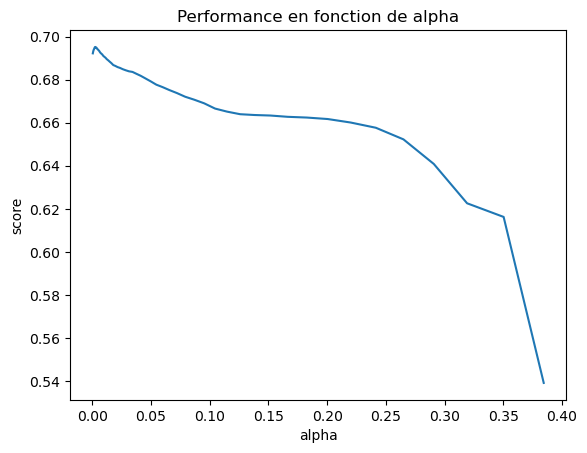

In [54]:
plt.plot(alphas, means)
plt.title("Performance en fonction de alpha")
plt.xlabel("alpha")
plt.ylabel("score")
plt.show()

In [55]:
alpha = 0.0025288732011953413

preprocess_cox_net = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ['CENTER', 'CYTO_LVL'])])

pipe_coxnet = make_pipeline(preprocess_cox_net, CoxnetSurvivalAnalysis(alphas=[alpha]))

fold_scores_coxnet, mean_score_coxnet = run_cv_cox(pipe_coxnet, X_train, y_train, cv, scorer)
print(fold_scores_coxnet, mean_score_coxnet)

   fold  train_sore  val_sore
0     0    0.698283  0.719340
1     1    0.697890  0.721010
2     2    0.706870  0.683978
3     3    0.712868  0.649699
4     4    0.701298  0.701975      mean       std
0  0.6952  0.029543


In [56]:
res_coxv3_vs_coxnet = ttest_rel(fold_scores_coxnet['val_sore'],fold_scores_cox_3['val_sore'])
print(f"t = {res_coxv3_vs_coxnet.statistic:.3f}, p = {res_coxv3_vs_coxnet.pvalue:.4f}")

t = 2.197, p = 0.0929


Le modèle avec régularisation Elastic Net montre un score de 0.6952 ± 0.029543. \
Le test de Student montre :
- t = 2.197
- p = 0.0929

### 5.6 Entrainement final du modèle

In [57]:
y_train = loader.make_surv_target(y_train['OS_YEARS'], y_train['OS_STATUS'])
y_test = loader.make_surv_target(y_test['OS_YEARS'], y_test['OS_STATUS'])

pipe_coxnet.fit(X_train, y_train)
risk_coxnet = pipe_coxnet.predict(X_test)
print(evaluation.ipcw_c_index(y_train, y_test, risk_coxnet))

0.6855597352973165


Nous obtenons un score de 0.6856 sur la totalité de notre dataset.

In [59]:
coefs_pipe_coxnet = pd.Series(
    pipe_coxnet[-1].coef_[:, np.argmin(np.abs(pipe_coxnet[-1].alphas_ - best_alpha))],
    index=pipe_coxnet[0].get_feature_names_out()
).sort_values()
coefs_pipe_coxnet

cat__CENTER_ROM              -0.386358
cat__CENTER_PV               -0.386123
cat__CYTO_LVL_NORMAL         -0.360921
cat__CENTER_CCH              -0.304124
num__HB                      -0.281933
cat__CENTER_TUD              -0.262111
num__PLT_LOG                 -0.239550
cat__CENTER_CGM              -0.187733
cat__CYTO_LVL_GOOD           -0.122240
cat__CYTO_LVL_VERY_GOOD      -0.108657
cat__CENTER_UOB              -0.045617
cat__CENTER_ICO               0.000000
cat__CENTER_GESMD             0.000000
cat__CENTER_FUCE              0.000000
cat__CENTER_REL               0.000000
cat__CENTER_HMS               0.000000
cat__CYTO_LVL_MISSING         0.000000
cat__CENTER_VU                0.000000
cat__CENTER_UMG               0.000000
cat__CENTER_MSK               0.000000
cat__CENTER_IHBT              0.000000
cat__CENTER_DUTH              0.000000
cat__CENTER_FLO               0.000000
cat__CYTO_LVL_INTERMEDIATE    0.029096
num__WBC_LOG                  0.036179
num__ANC_LOG             

Le modèle à mis a un coefficient 0 un certains nombre de centres (VU, MSK, ...), ainsi que CYTO_MISSING.\
On retrouve CYTO_LVL_VERY_POOR en tant que paramètre ayant le coefficient positif le plus important ainsi que les centres UOXF et MUV, et BM_BLAST.\
On retrouve aussi certains centre (ROM, PV) en tant que parmètre ayant un effet très négatif, ainsi que CYTO_LVL_NORMAL et HB.